# 306.3. Host galaxy association for low-z supernovae

<div style="max-width:300px; float: left; margin-right: 1em">

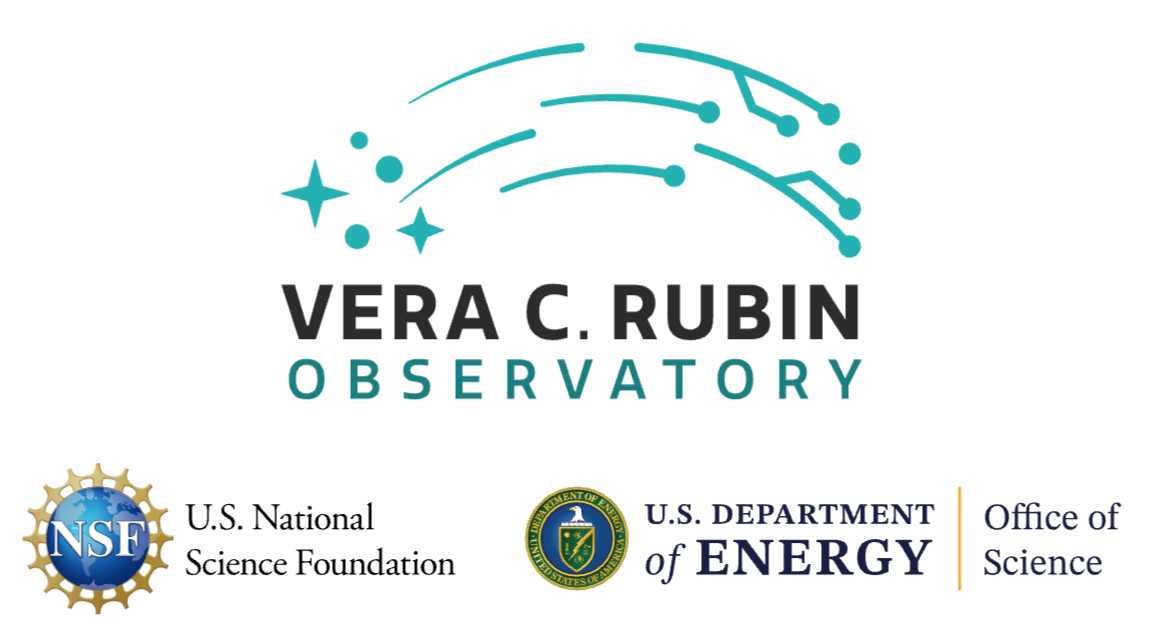

</div>

For the Rubin Science Platform at data.lsst.cloud.\
Data Release: [Data Preview 2](https://dp2.lsst.io/)\
Container Size: Large\
LSST Science Pipelines version: r30.0.11\
Last verified to run: 2026-10-27\
Repository: [github.com/lsst/tutorial-notebooks](https://github.com/lsst/tutorial-notebooks)\
DOI: [10.11578/rubin/dc.20250909.20](https://doi.org/10.11578/rubin/dc.20250909.20)

**Learning objective:** Understand the challenges in associating extragalactic time-domain objects with potential host galaxies in DP2.

**LSST data products:** `DiaObject`, `Object`, `deep_coadd`

**Packages:** `lsst.rsp`

**Credit:**
Originally developed by the Rubin Community Science team.
Please consider acknowledging them if this notebook is used for the preparation of journal articles, software releases, or other notebooks.

**Get Support:**
Everyone is encouraged to ask questions or raise issues in the 
<a href="https://community.lsst.org/c/support">Support Category</a> 
of the Rubin Community Forum.
Rubin staff will respond to all questions posted there.

## 1. Introduction

The identification of the true host galaxy for a given transient is an active area of research, and not always straightforward. 
The issue of background interloper galaxies that are "nearby" in 2D distance along the line of sight, but not physically associated with the transient, will become more challenging as the LSST progresses.
The process of host association ideally includes redshift estimates and also priors based on the transient and galaxy classifications, in addition to an assessment of 2D separation on the sky.

In this tutorial, the additional challenges of host association that stem from the short duration of DP2 data collection are presented, along with a few basic approaches to host association. It is intended as a beginner tutorial for anyone working on transient host galaxies, **and also intended as a cautionary tale to illustrate the challenges of low-redshift host association with DP2**.

**Deep coadd contamination.**\
The DP2 images were obtained between Apr 25 2025 and Jan 07 2026, but in some sky regions most of the images were obtained over a more constrained time frame. If that time frame happens to coincide with an extragalactic transient, the deep coadd images can be "contaminated" by its light, and the transient detected and reported in the `Object` table. This must be kept in mind and accounted for when identifying potential hosts in the `Object` table.

**Host association parameters.**\
The DP2 `DiaObject` table **does not contain** the host association parameters described in the Rubin Observatory Data Products Definitions Document ([DPDD](https://docushare.lsstcorp.org/docushare/dsweb/Get/LSE-163/LSE-163_DataProductsDefinitionDocumentDPDD.pdf)) and in the Data Management Tech Note "Host Galaxy Association for DIAObjects" ([DMTN-151](https://dmtn-151.lsst.io/)).
These future parameters are: (1) the three nearest point-like and extended Objects by 2D radial distance; (2) the three extended Objects with the lowest separations (using, e.g., second moments of the luminosity profile); and (3) the distance to the nearest low-redshift galaxy from a separate catalog (e.g., NED).
As there parameters are not included in the DP2 `DiaObject` table, this tutorial demonstrates how to use several of the galaxy shape parameters in the DP2 `Object` table to associate extragalactic transients with potential host galaxies.

In this notebook, three options for measuring the "separation" between SN coordinates and a potential host galaxy are demonstrated.

1. **2D sky distance:**
The offset, in arcseconds or pixels, between the SN coordinates and a potential host galaxy's centroid.

2. **Effective Kron separation:**
The Kron radius for a galaxy is based on the first image moment ([Kron 1980](https://ui.adsabs.harvard.edu/abs/1980ApJS...43..305K/abstract)).
It is more typically used for flux measurements than for galaxy size and shape, as twice the Kron radius will capture >90% of the galaxy flux.
In the `Object` table, the Kron radius for a given filter, e.g., `r_kronRad`, is the square root of the product of the semi-major and semi-minor axes of the galaxy, and it is given in units of pixels.
The _effective_ Kron separation is the distance bewteen the target and the galaxy barycenter, divided by the galaxy's Kron radius.

3. **Effective elliptical separation:**
This is based on the adaptive second moments of the galaxy's luminosity profile - the Hirata-Seljak-Mandelbaum (HSM) shape measurements, e.g., [Hirata and Seljak (2003)](https://ui.adsabs.harvard.edu/abs/2003MNRAS.343..459H/abstract) and [Mandelbaum et al. (2005)](https://ui.adsabs.harvard.edu/abs/2005MNRAS.361.1287M/abstract).
In the `Object` table, the second moments for the reference band are provided in the `shape_xx` ($Ixx$), `shape_yy` ($Iyy$), and `shape_xy` ($Ixy$) columns, in pixels.
The same measures are also provided per-band, e.g., `i_ixx`, `i_iyy`, and `i_ixy`.
Where $x$ and $y$ are RA and Declination, respectively, and $ \delta x = x_{SN}-x_{galaxy} $ and $ \delta y = y_{SN}-y_{galaxy} $ are also in pixels, the effective elliptical separation $R$ can be calculated with the equations below. See also <a href="https://sextractor.readthedocs.io/en/latest/Position.html#ellipse-parameters-cxx-cyy-cxy">this description and graphic of the ellipse parameters CXX, CYY, CXY in the Source Extractor documentation by E. Bertin</a>.
$$ C_{xx} = {I_{yy} \over {I_{xx}I_{yy} - I_{xy}^2}} $$ 
$$ C_{yy} = {I_{xx} \over {I_{xx}I_{yy} - I_{xy}^2}} $$ 
$$ C_{xy} = {-2 I_{xy} \over {I_{xx}I_{yy} - I_{xy}^2}} $$
$$ R^2 = C_{xx}(\delta x)^2 + C_{yy}(\delta y)^2 + C_{xy}(\delta x)(\delta y) $$

**Related tutorials:** The other 300-level tutorials in this series on extragalactic transients, the 200-level tutorials on deep coadd images and the `Object` table, and the 100-level tutorials on accessing catalogs with the TAP service, and image access and display.

### 1.1. Import packages

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import ZScaleInterval
from astropy.table import Table, join

import lsst.afw.display as afwDisplay
from lsst.rsp import RSPDiscovery
from lsst.daf.butler import Butler
from lsst.images import Box, Interval
from lsst.utils.plotting import (get_multiband_plot_colors,
                                 get_multiband_plot_symbols,
                                 get_multiband_plot_linestyles,
                                 set_rubin_plotstyle)

### 1.2. Define parameters and functions

Instantiate the tap service

In [ ]:
discovery = RSPDiscovery("dp2")
tap_service = discovery.get_tap_client()

Instatiate the Butler.

In [ ]:
butler = Butler('dp2', collections="dp2")

Set the style for plotting data.

In [ ]:
# set_rubin_plotstyle()
filter_colors = get_multiband_plot_colors()
filter_symbols = get_multiband_plot_symbols()
filter_linestyles = get_multiband_plot_linestyles()
filter_names = filter_colors.keys()

Set `afwDisplay` to use `matplotlib`.

In [ ]:
afwDisplay.setDefaultBackend("matplotlib")

## 2. Supernovae in DP2

Tutorial 306.2 cross-matches supernovae from the Transient Name Server with the DP2 `DiaObject` catalog. Use the five of these with the highest number of detections in DP2 as a small sample for this tutorial.

* [SN 2025mbp](https://www.wis-tns.org/object/2025mbp) - SN Ia at z=0.04616
* [SN 2026bbl](https://www.wis-tns.org/object/2026bbl) - SN II at z=0.1139
* [SN 2025hlf](https://www.wis-tns.org/object/2025hlf) - SN II at z=0.0732
* [SN 2025sfo](https://www.wis-tns.org/object/2025sfo) - SLSN-I at z=0.22
* [SN 2025imw](https://www.wis-tns.org/object/2025imw) - SN Ia at z=0.02

<div style="max-width:800px; float: left; margin-right: 1em">

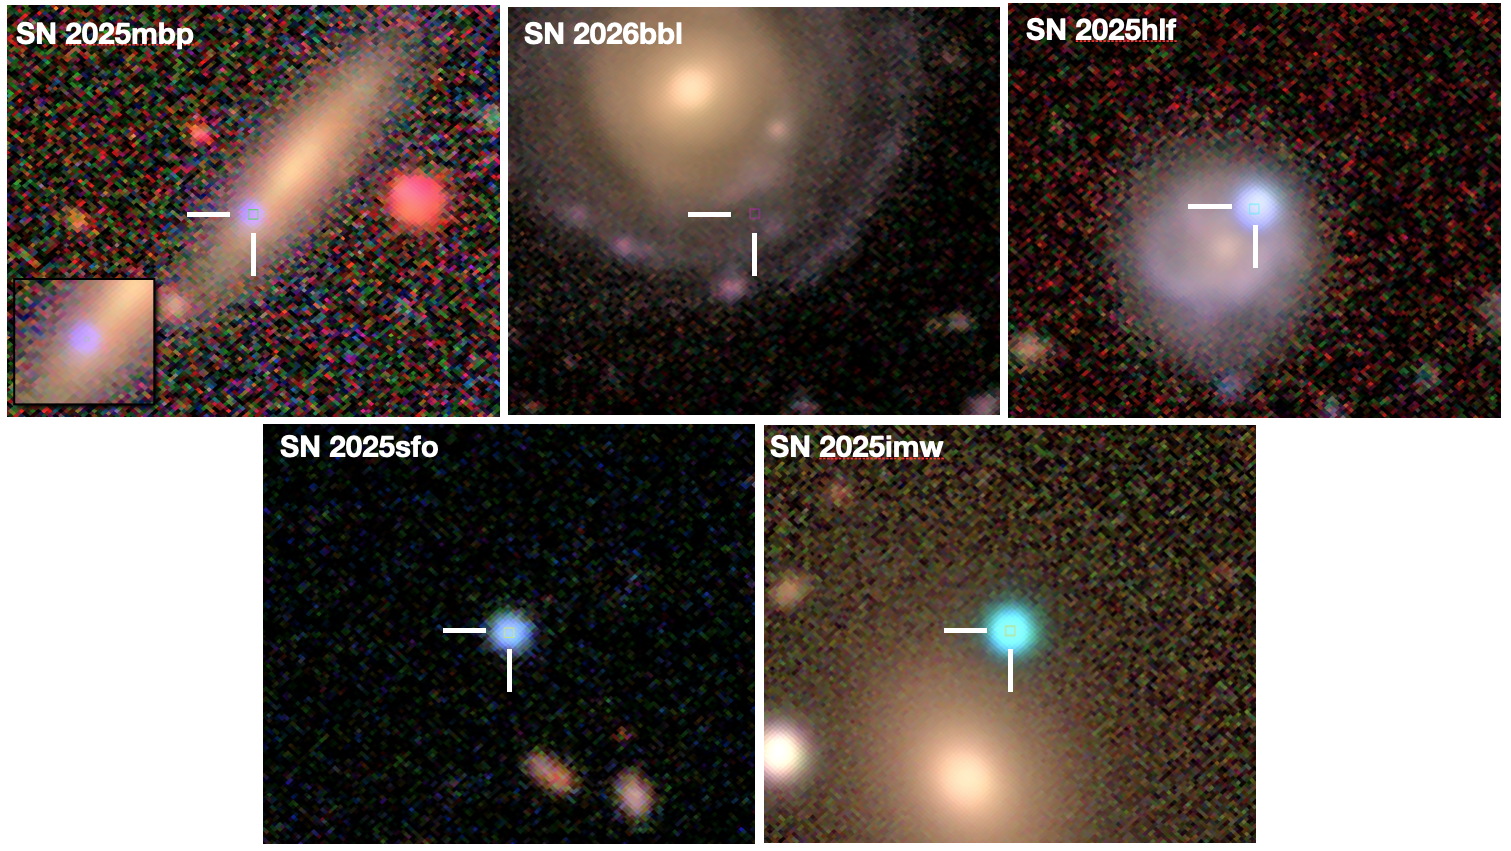

</div>

**Figure 1:** Cutouts of the DP2 HiPS deep coadd color images ($\sim$40" per side) centered on five cross-matched TNS supernovae (marked with white lines). Blue-ish point-like sources at the locations of four of the five indicate the SN light has contaminated the deep coadd image. For SN 2025mbp (upper left) the SN light is is subtle, and the inset shows it best. Only for SN 2026bbl (upper middle) is there is no obvious SN light in the color image.

Known host galaxy information:
* SN 2025mbp - the large inclined galaxy in which the SN is embedded is the confirmed host by redshift ([SN 2025mbp in WISeREP](https://www.wiserep.org/object/28251)).
* SN 2026bbl - the large face-on spiral galaxy in which the SN is embedded is the confirmed host by redshift ([SN 2026bbl in WISeREP](https://www.wiserep.org/object/29977) and the [SDSS spectrum of the galaxy](https://skyserver.sdss.org/dr16/en/tools/explore/Summary.aspx?id=1237651754534306014)).
* SN 2025hlf - the large face-on spiral galaxy in which the SN is embedded is the confirmed host by redshift ([SN 2025hlf in WISeREP](https://www.wiserep.org/object/28233) and the [SDSS spectrum of the galaxy](https://skyserver.sdss.org/dr16/en/tools/explore/Summary.aspx?id=1237658491208204508))
* SN 2025sfo - no confirmed host, but there appears to be a faint point-like source at the location in pre-SN images, see [SN 2025sfo in TNS](https://www.wis-tns.org/object/2025sfo).
* SN 2025imw - no confirmed host, and the by-eye likely host *seems* to be the large bright elliptical to the south of the SN but... see also Section 5!

Define a table of the SN names and `diaObjectId` values.

In [ ]:
sns = ['SN 2025mbp', 'SN 2026bbl', 'SN 2025hlf', 'SN 2025sfo', 'SN 2025imw']
ids = [786352299365629972, 788015379422118937, 794819432252702737, 767356243130974229, 764124984615370762]
sn_table = Table([sns, ids], names=('sn_name', 'diaObjectId'))

Get the coordinates and number of detections from the `DiaObject` table.

In [ ]:
id_list = "(" + ", ".join(str(value) for value in sn_table['diaObjectId']) + ")"
query = """SELECT diaObjectId, ra, dec, nDiaSources FROM dp2.DiaObject WHERE diaObjectId IN {}""".format(id_list)
job = tap_service.submit_job(query)
job.run()
job.wait(phases=['COMPLETED', 'ERROR'])
print('Job phase is', job.phase)
if job.phase == 'ERROR':
    job.raise_if_error()
assert job.phase == 'COMPLETED'
dia_objects = job.fetch_result().to_table()

Join `sn_table` and `dia_objects` to create the `targets` table and sort by `nDiaSources`.

In [ ]:
targets = join(sn_table, dia_objects, keys='diaObjectId')
targets.sort('nDiaSources', reverse=True)

Option to display the table.

In [ ]:
# targets

Retrieve the forced difference-image photometry (the lightcurves) from the `ForcedSourceOnDiaObject` table.

In [ ]:
query = """SELECT fsodo.diaObjectId, fsodo.psfDiffFlux, fsodo.psfDiffFluxErr, fsodo.band, v.expMidptMJD
        FROM dp2.ForcedSourceOnDiaObject AS fsodo
        JOIN dp2.Visit AS v ON v.visit = fsodo.visit
        WHERE fsodo.diaObjectId IN {}""".format(id_list)
job = tap_service.submit_job(query)
job.run()
job.wait(phases=['COMPLETED', 'ERROR'])
print('Job phase is', job.phase)
if job.phase == 'ERROR':
    job.raise_if_error()
assert job.phase == 'COMPLETED'
flux_table = job.fetch_result().to_table()

Option to display the table.

In [ ]:
# flux_table

Display the forced difference-image flux lightcurves. Recall that, because the template coadd images can also be contaminated by transient flux, difference-image fluxes can be $<$0 when the SN is brighter in the template coadd than in the visit image. Include a horizontal line at flux = 0 to guide the eye.

In [ ]:
for i in range(len(targets)):
    fig = plt.figure(figsize=(10, 3))
    plt.axhline(0, alpha=0.2, color='grey')
    for f, filt in enumerate(filter_names):
        fx = np.where((flux_table['diaObjectId'] == targets['diaObjectId'][i]) & (flux_table['band'] == filt))[0]
        plt.errorbar(flux_table['expMidptMJD'][fx], flux_table['psfDiffFlux'][fx],
                     yerr=flux_table['psfDiffFluxErr'][fx], fmt=filter_symbols[filt],
                     ms=10, mew=0, alpha=0.5, color=filter_colors[filt], label=filt)
    plt.xlabel('Modified Julian Date', fontsize=12)
    plt.ylabel('Flux (nJy)', fontsize=12)
    plt.legend(loc='best', ncol=2, fontsize=12)
    plt.title(targets['sn_name'][i] + ", LSST-DP2-DO-" + str(targets['diaObjectId'][i]))
    plt.show()

>**Figure 2:** The forced difference-image flux vs. modified Julian date for the 5 targeted transients. This plot shows the diversity in their lightcurves. The fact that some extend to negative difference-image flux indicates that the template coadd image contained light from the transient itself.

## 3. Check for deep coadd contamination

**Checking a deep coadd image for SN flux contamination is not a typical step of the host association process.** However, for DP2, and especially for transients that were detected in a large fraction of the DP2 images (like the 5 selected transients), a visual check of the deep coadd images (Section 3.1) and a cross-match between the deep coadd input visit dates and the dates when the transient was bright (Section 3.2) make for a useful demonstration.

### 3.1. Display the deep coadd images

Display the deep coadd images in each filter $ugrizy$ in order to explore by eye any contamination by transient light.

For each target, create a grid plot of deep coadd image cutouts centered on the transient's coordinates.

In [ ]:
subset_size = 150
for i in range(len(targets)):
    query = """band.name = :band AND patch.region OVERLAPS POINT(:ra, :dec)"""
    binder = {"band": 'i', "ra": targets['ra'][i], "dec": targets['dec'][i]}
    refs = butler.query_datasets("deep_coadd", where=query, bind=binder)
    data_id = refs[0].dataId
    use_tract = data_id['tract']
    use_patch = data_id['patch']
    wcs = butler.get("deep_coadd.sky_projection", dataId=data_id)
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    selection_bbox = Box.factory[round(sn_xy.y):round(sn_xy.y)+1,
                                 round(sn_xy.x):round(sn_xy.x)+1].padded(subset_size)
    params = {'bbox': selection_bbox}

    cutouts = []
    cutout_ok = []
    for filt in ['u', 'g', 'r', 'i', 'z', 'y']:
        try:
            query = """band.name = '{}' AND tract.id = {} AND patch IN ({})""".format(filt, use_tract, use_patch)
            refs = butler.query_datasets("deep_coadd", where=query)
            subset = butler.get(refs[0], parameters=params)
            cutouts.append(subset)
            cutout_ok.append(True)
            del subset
        except:
            cutouts.append([])
            cutout_ok.append(False)

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(8, 3))
    axes = axes.flatten()
    for f, filt in enumerate(['u', 'g', 'r', 'i', 'z', 'y']):
        if cutout_ok[f]:
            img_array = cutouts[f].image.array
            cutout_extent = (cutouts[f].bbox.x.start, cutouts[f].bbox.x.stop,
                             cutouts[f].bbox.y.start, cutouts[f].bbox.y.stop)
            zscale = ZScaleInterval(krej=1)
            vmin, vmax = zscale.get_limits(img_array)
            norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
            axes[f].imshow(img_array, cmap='gray', norm=norm, extent=cutout_extent, origin='lower')
            axes[f].set_title(filt)
            axes[f].axis("off")
            axes[f].plot(sn_xy.x, sn_xy.y, 's', ms=10, mew=1, color='None', mec='cyan')
            del img_array
        else:
            axes[f] = axes[f]
            axes[f].remove()
    plt.suptitle(targets['sn_name'][i] + ", LSST-DP2-DO-" + str(targets['diaObjectId'][i]), y=0.8)
    plt.tight_layout()
    plt.show()
    
    del cutouts

>**Figure 3:** From left to right, the $ugrizy$ deep coadd image cutouts, $\sim$60x60 arcsec, with the SN's location marked with a cyan square. In all images except the $ugzy$-band cutouts of SN 2026bbl, and the $y$-band cutout of SN 2025mbp, a point source a the SN's location is obvious.

### 3.2. Review the deep coadd input dates

Display again the SN lightcurves, but mark which epochs contributed to the deep coadd image.
If the deep coadd image was built mostly from visits that were obtained while a transient was bright, it is more likely that the deep coadd image will be contaminated with SN flux.

Retrieve the $i$-band deep coadd image in order to use its grid index to figure out which cell the SN's location falls in. For a refresher on the cell-based nature of deep coadd images, see the [What's new with DP2 images](https://dp2.lsst.io/products/images/new_lsst_image_format.html) webpage or the 200-level tutorial on deep coadd images.
Collect all the input visits for each target in one table.

In [ ]:
temp0 = []
temp1 = []
temp2 = []
for i in range(len(targets)):
    query = """band.name = :band AND patch.region OVERLAPS POINT(:ra, :dec)"""
    binder = {"band": 'i', "ra": targets['ra'][i], "dec": targets['dec'][i]}
    refs = butler.query_datasets("deep_coadd", where=query, bind=binder)
    data_id = refs[0].dataId
    use_tract = data_id['tract']
    use_patch = data_id['patch']
    deep_coadd = butler.get("deep_coadd", dataId=data_id)
    wcs = deep_coadd.sky_projection
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    cij = deep_coadd.grid.index_of(x=sn_xy.x, y=sn_xy.y)
    del deep_coadd

    for filt in ['u', 'g', 'r', 'i', 'z', 'y']:
        try:
            query = """band.name = '{}' AND tract.id = {} AND patch IN ({})""".format(filt, use_tract, use_patch)
            refs = butler.query_datasets("deep_coadd", where=query)
            data_id = refs[0].dataId
            provenance = butler.get("deep_coadd.provenance", dataId=data_id)
            contributions = provenance.contributions
            tx = np.where((contributions['cell_i'] == cij.i) & (contributions['cell_j'] == cij.j))[0]
            for x in tx:
                temp0.append(targets['diaObjectId'][i])
                temp1.append(int(contributions['visit'][x]))
                temp2.append(filt)
        except:
            pass
inputs = Table([temp0, temp1, temp2], names=['diaObjectId', 'visit', 'band'])
del temp0, temp1, temp2

Retrieve the date of each visit from the `Visit` table.

In [ ]:
visit_list = "(" + ", ".join(str(value) for value in inputs['visit']) + ")"
query = """SELECT visit, expMidptMJD FROM dp2.Visit WHERE visit IN {}""".format(visit_list)
job = tap_service.submit_job(query)
job.run()
job.wait(phases=['COMPLETED', 'ERROR'])
print('Job phase is', job.phase)
if job.phase == 'ERROR':
    job.raise_if_error()
visits = job.fetch_result().to_table()

Join the tables of inputs and visit dates.

In [ ]:
input_visits = join(inputs, visits, keys='visit')

Option to display the input visits table.

In [ ]:
# input_visits

Display the SN lightcurve as in Figure 2, and mark dates that were used as input visits to the deep coadd image with vertical gray lines.

In [ ]:
for i in range(len(targets)):
    fig = plt.figure(figsize=(10, 3))
    plt.axhline(0, alpha=0.2, color='grey')
    for f, filt in enumerate(filter_names):
        fx = np.where((input_visits['diaObjectId'] == targets['diaObjectId'][i]) & (input_visits['band'] == filt))[0]
        if len(fx) > 0:
            for x in fx:
                plt.axvline(input_visits['expMidptMJD'][x], lw=1, alpha=0.2, color=filter_colors[filt])
    for f, filt in enumerate(filter_names):
        fx = np.where((flux_table['diaObjectId'] == targets['diaObjectId'][i]) & (flux_table['band'] == filt))[0]
        plt.errorbar(flux_table['expMidptMJD'][fx], flux_table['psfDiffFlux'][fx],
                     yerr=flux_table['psfDiffFluxErr'][fx], fmt=filter_symbols[filt],
                     ms=10, mew=0, alpha=0.5, color=filter_colors[filt], label=filt)
    plt.xlabel('Modified Julian Date', fontsize=12)
    plt.ylabel('Flux (nJy)', fontsize=12)
    plt.legend(loc='best', ncol=2, fontsize=12)
    plt.title(targets['sn_name'][i] + ", LSST-DP2-DO-" + str(targets['diaObjectId'][i]))
    plt.show()

>**Figure 4:** Each transient's lightcurve with vertical lines marking visits that contributed to the deep coadd image. The filters for which the input visits included dates where the SN was bright are more likely to exhibit SN light in their deep coadd image in Figure 3.

## 4. Cross-match to the Object table

Cross-matching to the `Object` table is the typical first step in host association.

Query the `Object` table using a 30 arcsecond radius around each target (**see Section 5 for a demonstration of how this can be too small for low-redshift transients**).
Retreive the $i$-band photometry, Kron radius, and HSM moments, and the extendedness parameters in the reference band for each object.
Require that the $i$-band flux have a signal-to-noise ratio greater than 5.

In [ ]:
rad_deg = 30.0/3600.0
query = """SELECT ut.sn_name, ut.diaObjectId, ut.ra, ut.dec, ut.nDiaSources,
        o.objectId, o.coord_ra, o.coord_dec, o.refBand, o.refExtendedness, o.refSizeExtendedness,
        o.i_psfFlux, o.i_psfFluxErr, o.i_psfFlux_flag, o.i_cModelFlux, o.i_cModelFluxErr, o.i_cModel_flag,
        o.i_kronRad, o.i_kronFlux_flag, o.i_kronFlux_flag_bad_radius,
        o.i_ixx, o.i_ixy, o.i_iyy, o.i_hsm_moments_flag,
        DISTANCE(POINT('ICRS', o.coord_ra, o.coord_dec), POINT('ICRS', ut.ra, ut.dec))*3600 AS distance_arcsec
        FROM dp2.Object AS o
        JOIN TAP_UPLOAD.ut AS ut
        ON DISTANCE(POINT('ICRS', o.coord_ra, o.coord_dec),
                    POINT('ICRS', ut.ra, ut.dec)) < {}
        WHERE o.i_psfFlux/o.i_psfFluxErr > 5 OR o.i_cModelFlux/o.i_cModelFluxErr > 5
        """.format(rad_deg)
job = tap_service.submit_job(query, uploads={"ut": targets})
job.run()
job.wait(phases=['COMPLETED', 'ERROR'])
print('Job phase is', job.phase)
if job.phase == 'ERROR':
    job.raise_if_error()
assert job.phase == 'COMPLETED'
objects = job.fetch_result().to_table()

Option to display the table.

In [ ]:
# objects

For each target, retrieve the $i$-band cutout.

In [ ]:
cutouts = []
for i in range(len(targets)):
    query = """band.name = :band AND patch.region OVERLAPS POINT(:ra, :dec)"""
    binder = {"band": 'i', "ra": targets['ra'][i], "dec": targets['dec'][i]}
    refs = butler.query_datasets("deep_coadd", where=query, bind=binder)
    data_id = refs[0].dataId
    use_tract = data_id['tract']
    use_patch = data_id['patch']
    wcs = butler.get("deep_coadd.sky_projection", dataId=data_id)
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    subset_size = 150
    selection_bbox = Box.factory[round(sn_xy.y):round(sn_xy.y)+1,
                                 round(sn_xy.x):round(sn_xy.x)+1].padded(subset_size)
    params = {'bbox': selection_bbox}
    query = """band.name = 'i' AND tract.id = {} AND patch IN ({})""".format(use_tract, use_patch)
    refs = butler.query_datasets("deep_coadd", where=query)
    subset = butler.get(refs[0], parameters=params)
    cutouts.append(subset)
    del subset

Display the $i$-band cutouts and mark objects.

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
axes = axes.flatten()
for i in range(len(targets)):
    subset = cutouts[i]
    wcs = subset.sky_projection
    subset_extent = (subset.bbox.x.start, subset.bbox.x.stop,
                     subset.bbox.y.start, subset.bbox.y.stop)
    img_array = subset.image.array
    zscale = ZScaleInterval(krej=1)
    vmin, vmax = zscale.get_limits(img_array)
    norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
    axes[i].imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
    tx = np.where(objects['diaObjectId'] == targets['diaObjectId'][i])[0]
    for x in tx:
        color = 'limegreen'
        symbol = 'o'
        if (objects['refExtendedness'][x] == 0) or (objects['refSizeExtendedness'][x] < 0.5) or (objects['refExtendedness'].mask[x]):
            color='yellow'
        if objects['distance_arcsec'][x] < 0.5:
            symbol = 's'
        coord = SkyCoord(objects['coord_ra'][x], objects['coord_dec'][x], unit="deg")
        xy = wcs.sky_to_pixel(coord)
        axes[i].plot(xy.x, xy.y, symbol, ms=10, color='None', mec=color, mew=1)
    axes[i].set_title(targets['sn_name'][i])
    axes[i].axis("off")
    del subset
axes[5].remove()
plt.tight_layout()
plt.show()

>**Figure 5:** The $i$-band cutout images, centered on the transients' coordinates, with nearby objects marked. The default marker type is a green circle, but the marker will be a square for any object within 0.5 arcseconds (likely the transient itself), or yellow if the object **was not** identified as likely to be extended (and thus less likely to be a host galaxy for the low-redshift SN).

### 4.1. Is the transient in the Object table

Check if there is an object within 0.5 arcseconds of the transient's coordinates from the `DiaObject` table.

*In general*, finding a very close object does not necessarily mean that it is the transient; especially at higher redshifts, host galaxies can be point-like and angular separations between transient and host can be very low.
This may be the case for SN 2025sfo, especially since Figure 4 shows that relatively fewer deep coadd inputs came from the time when that SN was bright.
However, for the other four low-redshift supernovae in DP2, given what was demonstrated about input visits contributing to the deep coadd image, it is more likely that in it is the transient in the object table.

Print the objects within 0.5 of each target.

In [ ]:
tx = np.where(objects['distance_arcsec'] < 0.5)[0]
objects[tx]

### 4.2. Nearest objects

Option to print the three nearest objects by 2D distance (angular offset) for each of the targets.

In [ ]:
# cols = ['sn_name', 'objectId', 'distance_arcsec', 'i_cModelFlux']
# for i in range(len(targets)):
#     print('')
#     tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
#                   (objects['distance_arcsec'] > 0.5))[0]
#     temp = objects[tx]
#     temp.sort('distance_arcsec')
#     print(temp[cols][0:3])

Mark the three nearest objects by 2D distance on the $i$-band cutout for each target.

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
axes = axes.flatten()
for i in range(len(targets)):
    subset = cutouts[i]
    wcs = subset.sky_projection
    subset_extent = (subset.bbox.x.start, subset.bbox.x.stop,
                     subset.bbox.y.start, subset.bbox.y.stop)
    img_array = subset.image.array
    zscale = ZScaleInterval(krej=1)
    vmin, vmax = zscale.get_limits(img_array)
    norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
    axes[i].imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    axes[i].plot(sn_xy.x, sn_xy.y, 's', ms=10, color='None', mec='cyan', mew=1)
    tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
                  (objects['distance_arcsec'] > 0.5))[0]
    temp = objects[tx]
    temp.sort('distance_arcsec')
    for x in range(3):
        color = 'limegreen'
        symbol = 'o'
        if (temp['refExtendedness'][x] == 0) or (temp['refSizeExtendedness'][x] < 0.5) or (temp['refExtendedness'].mask[x]):
            color='yellow'
        coord = SkyCoord(temp['coord_ra'][x], temp['coord_dec'][x], unit="deg")
        xy = wcs.sky_to_pixel(coord)
        axes[i].plot(xy.x, xy.y, symbol, ms=10, color='None', mec=color, mew=1)
        axes[i].text(xy.x + 5, xy.y + 5, str(x+1), fontsize=15, color=color)
    axes[i].set_title(targets['sn_name'][i])
    axes[i].axis("off")
    del subset
axes[5].remove()
plt.tight_layout()
plt.show()

>**Figure 6:** Similar to Figure 5, but only the transient's coordinates (cyan square) and the three nearest objects by 2D distance (angular offset) are marked with green circles, or yellow circles if the object **was not** identified as likely to be extended (and thus less likely to be a host galaxy for the low-redshift SN).

Takeaways:
* SN 2025mbp - the nearest extended object (green 1) is also the confirmed host.
* SN 2026bbl - none of the three nearest objects are the confirmed host.
* SN 2025hlf - the nearest object (yellow 1) is also the confirmed host, but its parameters do not indicate its extendedness.
* SN 2025sfo - the situation is unclear.
* SN 2025imw - none of the three nearest objects are the potential large elliptical host.

### 4.3. Nearest extended objects

Option to print the three nearest *extended* objects by 2D distance (angular offset) for each of the targets.

In [ ]:
# cols = ['sn_name', 'objectId', 'distance_arcsec', 'i_cModelFlux', 'refExtendedness', 'refSizeExtendedness']
# for i in range(len(targets)):
#     print('')
#     tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
#                   (objects['distance_arcsec'] > 0.5) &
#                   ((objects['refExtendedness'] == 1) | (objects['refSizeExtendedness'] >= 0.5)))[0]
#     temp = objects[tx]
#     temp.sort('distance_arcsec')
#     print(temp[cols][0:3])

Mark the three nearest extended objects by 2D distance on the $i$-band cutout for each target.

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
axes = axes.flatten()
for i in range(len(targets)):
    subset = cutouts[i]
    wcs = subset.sky_projection
    subset_extent = (subset.bbox.x.start, subset.bbox.x.stop,
                     subset.bbox.y.start, subset.bbox.y.stop)
    img_array = subset.image.array
    zscale = ZScaleInterval(krej=1)
    vmin, vmax = zscale.get_limits(img_array)
    norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
    axes[i].imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    axes[i].plot(sn_xy.x, sn_xy.y, 's', ms=10, color='None', mec='cyan', mew=1)
    tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
                  (objects['distance_arcsec'] > 0.5) &
                  ((objects['refExtendedness'] == 1) | (objects['refSizeExtendedness'] >= 0.5)))[0]
    temp = objects[tx]
    temp.sort('distance_arcsec')
    for x in range(3):
        coord = SkyCoord(temp['coord_ra'][x], temp['coord_dec'][x], unit="deg")
        xy = wcs.sky_to_pixel(coord)
        axes[i].plot(xy.x, xy.y, symbol, ms=10, color='None', mec='limegreen', mew=1)
        axes[i].text(xy.x + 5, xy.y + 5, str(x+1), fontsize=15, color='limegreen')
    axes[i].set_title(targets['sn_name'][i])
    axes[i].axis("off")
    del subset
axes[5].remove()
plt.tight_layout()
plt.show()

>**Figure 7:** Similar to Figures 5 and 6, but only the transient's coordinates (cyan square) and the three nearest *likely extended* objects by 2D distance (angular offset) are marked with green circles.

Takeaways:
* SN 2025mbp - the nearest extended object (green 1) is also the confirmed host.
* SN 2026bbl - the second-nearest extended object (green 2) is also the confirmed host - but not the nearest.
* SN 2025hlf - none of the nearest extended objects are the confirmed host (its parameters did not indicate its extendedness).
* SN 2025sfo - the situation is unclear.
* SN 2025imw - none of the three nearest extended objects are the potential large elliptical host.

### 4.4. Nearest extended objects by Kron radius

Calculate the *effective* Kron separation, which was introduced and described in Section 1.

In [ ]:
objects['distance_pix'] = objects['distance_arcsec'] / 0.2
objects['eff_kron_sep'] = objects['distance_pix'] / objects['i_kronRad']

Option to print the three nearest extended objects, by the measure of `eff_kron_sep`, that also have an unflagged Kron radius.

In [ ]:
# cols = ['sn_name', 'distance_arcsec', 'i_cModelFlux', 'i_kronRad', 'eff_kron_sep']
# for i in range(len(targets)):
#     print('')
#     tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
#                   (objects['distance_arcsec'] > 0.5) &
#                   (objects['i_kronFlux_flag'] == False) & (objects['i_kronFlux_flag_bad_radius'] == False) &
#                   ((objects['refExtendedness'] == 1) | (objects['refSizeExtendedness'] >= 0.5)))[0]
#     temp = objects[tx]
#     temp.sort('eff_kron_sep')
#     print(temp[cols][0:3])

Mark the three nearest extended objects by effective Kron separation on the $i$-band cutout for each target.

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
axes = axes.flatten()
for i in range(len(targets)):
    subset = cutouts[i]
    wcs = subset.sky_projection
    subset_extent = (subset.bbox.x.start, subset.bbox.x.stop,
                     subset.bbox.y.start, subset.bbox.y.stop)
    img_array = subset.image.array
    zscale = ZScaleInterval(krej=1)
    vmin, vmax = zscale.get_limits(img_array)
    norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
    axes[i].imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    axes[i].plot(sn_xy.x, sn_xy.y, 's', ms=10, color='None', mec='cyan', mew=1)    
    tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
                  (objects['distance_arcsec'] > 0.5) &
                  (objects['i_kronFlux_flag_bad_radius'] == False) &
                  ((objects['refExtendedness'] == 1) | (objects['refSizeExtendedness'] >= 0.5)))[0]
    temp = objects[tx]
    temp.sort('eff_kron_sep')
    for x in range(3):
        coord = SkyCoord(temp['coord_ra'][x], temp['coord_dec'][x], unit="deg")
        xy = wcs.sky_to_pixel(coord)
        axes[i].plot(xy.x, xy.y, symbol, ms=10, color='None', mec='orange', mew=1)
        axes[i].text(xy.x + 5, xy.y + 5, str(x+1), fontsize=15, color='orange')
    axes[i].set_title(targets['sn_name'][i])
    axes[i].axis("off")
    del subset
axes[5].remove()
plt.tight_layout()
plt.show()

>**Figure 8:** Similar to Figures 5, 6, and 7, but only the transient's coordinates (cyan square) and the three nearest likely extended objects by effective Kron separation are marked with orange circles.

Takeaways:
* SN 2025mbp - the nearest extended object (orange 1) is also the confirmed host.
* SN 2026bbl - the second-nearest extended object (orange 2) is also the confirmed host - but not the nearest.
* SN 2025hlf - none of the nearest extended objects are the confirmed host.
* SN 2025sfo - the situation is unclear.
* SN 2025imw - the nearest extended object (orange 1) is also the *potential* large elliptical host (but see Section 5).

### 4.5. Nearest objects by HSM moments

Calculate the effective elliptical radius based on HSM moments, which was introduced and described in Section 1.

In [ ]:
objects['x'] = np.zeros(len(objects), dtype='float')
objects['y'] = np.zeros(len(objects), dtype='float')
objects['hsm_r'] = np.zeros(len(objects), dtype='float')
for i in range(len(targets)):
    subset = cutouts[i]
    wcs = subset.sky_projection
    tx = np.where(objects['diaObjectId'] == targets['diaObjectId'][i])[0]
    coords = SkyCoord(objects['coord_ra'][tx], objects['coord_dec'][tx], unit="deg")
    xy = wcs.sky_to_pixel(coords)
    objects['x'][tx] = xy.x
    objects['y'][tx] = xy.y
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    sn_x = sn_xy.x
    sn_y = sn_xy.y
    xr = sn_x - objects['x'][tx]
    yr = sn_y - objects['y'][tx]
    Cxx = objects['i_iyy'][tx] / ((objects['i_ixx'][tx] * objects['i_iyy'][tx]) - objects['i_ixy'][tx])
    Cyy = objects['i_ixx'][tx] / ((objects['i_ixx'][tx] * objects['i_iyy'][tx]) - objects['i_ixy'][tx])
    Cxy = -2.0 * (objects['i_ixy'][tx]) / ((objects['i_ixx'][tx] * objects['i_iyy'][tx]) - objects['i_ixy'][tx])
    objects['hsm_r'][tx] = np.sqrt((Cxx * xr**2) + (Cyy * yr**2) + (Cxy * xr * yr))

Option to print the three nearest extended objects, by the measure of `hsm_r`, that also have an unflagged HSM moments measurements.

In [ ]:
# cols = ['sn_name', 'distance_arcsec', 'i_cModelFlux', 'hsm_r']
# for i in range(len(targets)):
#     print('')
#     tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
#                   (objects['distance_arcsec'] > 0.5) &
#                   (objects['i_hsm_moments_flag'] == False) &
#                   ((objects['refExtendedness'] == 1) | (objects['refSizeExtendedness'] >= 0.5)))[0]
#     temp = objects[tx]
#     temp.sort('hsm_r')
#     print(temp[cols][0:3])

Mark the three nearest extended objects by effective elliptical radius on the $i$-band cutout for each target.

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
axes = axes.flatten()
for i in range(len(targets)):
    subset = cutouts[i]
    wcs = subset.sky_projection
    subset_extent = (subset.bbox.x.start, subset.bbox.x.stop,
                     subset.bbox.y.start, subset.bbox.y.stop)
    img_array = subset.image.array
    zscale = ZScaleInterval(krej=1)
    vmin, vmax = zscale.get_limits(img_array)
    norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
    axes[i].imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
    sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
    sn_xy = wcs.sky_to_pixel(sn_coord)
    axes[i].plot(sn_xy.x, sn_xy.y, 's', ms=10, color='None', mec='cyan', mew=1)    
    tx = np.where((objects['diaObjectId'] == targets['diaObjectId'][i]) &
                  (objects['distance_arcsec'] > 0.5) &
                  (objects['i_hsm_moments_flag'] == False) &
                  ((objects['refExtendedness'] == 1) | (objects['refSizeExtendedness'] >= 0.5)))[0]
    temp = objects[tx]
    temp.sort('hsm_r')
    for x in range(3):
        coord = SkyCoord(temp['coord_ra'][x], temp['coord_dec'][x], unit="deg")
        xy = wcs.sky_to_pixel(coord)
        axes[i].plot(xy.x, xy.y, symbol, ms=10, color='None', mec='magenta', mew=1)
        axes[i].text(xy.x + 5, xy.y + 5, str(x+1), fontsize=15, color='magenta')
    axes[i].set_title(targets['sn_name'][i])
    axes[i].axis("off")
    del subset
axes[5].remove()
plt.tight_layout()
plt.show()

>**Figure 9:** Similar to Figures 5, 6, 7, and 8, but only the transient's coordinates (cyan square) and the three nearest likely extended objects by effective elliptical radius, derived from the HSM second moments, are marked with magenta circles.

Takeaways:
* SN 2025mbp - none of the the nearest extended objects are also the confirmed host.
* SN 2026bbl - the second-nearest extended object (magenta 2) is also the confirmed host - but not the nearest.
* SN 2025hlf - none of the nearest extended objects are the confirmed host.
* SN 2025sfo - the situation is unclear.
* SN 2025imw - the second-nearest extended object (magenta 2) is also the *potential* large elliptical host (but see Section 5).

## 5. Summary of the challenges presented

This section reviews the main lessons learned about host association with DP2 objects and deep coadd images.

### 5.1. Deep coadds can contain transient light

For example, SN 2025sfo is the highest redshift SN of the five used in this tutorial, and it is a type SLSN-I which are known to occur in faint, dwarf, star-forming galaxies. 
In pre-SN images from the [DECam Legacy Survey](https://www.legacysurvey.org/viewer?ra=320.073119&dec=-17.208876&mark=320.073119%2C-17.208876&zoom=16&layer=ls-dr10) and from [PanSTARRS](https://ps1images.stsci.edu/cgi-bin/ps1cutouts?filter=color&verbose=0&filetypes=stack&pos=320.073118512-17.2088758337&size=400), a very small source is visible at the SN's location. For SN 2025sfo, the point-source in the DP2 deep coadd image could be the host galaxy, or the SN light, or a mix of both.

In Figure 4, it appears that DP2 includes several pre-SN visits. Although it is beyond the scope of this tutorial, a custom deep coadd image could be generated with only pre-SN inputs to better explore the host galaxy.

### 5.2. Extendedness estimates can be inaccurate

The confirmed host galaxy for SN 2025hlf is a face-on spiral. However, in the DP2 `Object` table that object's extendedness parameters did not indicate that it was extended, and its $i$-band `cModel` fluxes (appropriate for extended objects) were not populated, only the PSF fluxes. This caused that object to be misinterpreted as a point-like source and not be considered as a potential host in Section 4.3, 4.4, or 4.5.

A closer look at this galaxy's parameters in the `Object` table reveal flags related to the Kron and HSM measurements, as well as the deblending process. A deeper dive into *why* the deblending and measurement steps may not have worked correctly for this particular galaxy is beyond the scope of this tutorial. Look for other tutorials on interpreting the deblender outputs and rerunning source detection. The main takeaway point is that extendedness parameters can be inaccurate for extended low-redshift galaxies, and that should be kept in mind during host association analyses.

In [ ]:
object_id = 794819432252726615
query = """SELECT objectId, coord_ra, coord_dec, refBand, refExtendedness, refSizeExtendedness,
        i_psfFlux, i_psfFluxErr, i_psfFlux_flag, i_cModelFlux, i_cModelFluxErr, i_cModel_flag,
        i_kronRad, i_kronFlux_flag, i_kronFlux_flag_bad_radius,
        i_ixx, i_ixy, i_iyy, i_hsm_moments_flag, i_blendedness_flag, detect_fromBlend, deblend_blendNChild, deblend_parentNChild
        FROM dp2.Object WHERE objectId = {}""".format(object_id)
job = tap_service.submit_job(query, uploads={"ut": targets})
job.run()
job.wait(phases=['COMPLETED', 'ERROR'])
print('Job phase is', job.phase)
if job.phase == 'ERROR':
    job.raise_if_error()
assert job.phase == 'COMPLETED'
objects_2025hlf = job.fetch_result().to_table()

In [ ]:
objects_2025hlf

### 5.3. For low-z SN, potential hosts can have large offsets

For this example, use SN 2025imw.

In [ ]:
i = 4
targets[i]

Retrieve objects within 60 arcsec, instead of 30 arcsec as done above.

In [ ]:
rad_deg = 60.0/3600.0
sn_ra = targets['ra'][i]
sn_dec = targets['dec'][i]
query = """SELECT objectId, coord_ra, coord_dec, refBand, refExtendedness, refSizeExtendedness,
        i_psfFlux, i_psfFluxErr, i_psfFlux_flag, i_cModelFlux, i_cModelFluxErr, i_cModel_flag,
        i_kronRad, i_kronFlux_flag, i_kronFlux_flag_bad_radius, i_ixx, i_ixy, i_iyy, i_hsm_moments_flag,
        DISTANCE(POINT('ICRS', coord_ra, coord_dec), POINT('ICRS', {}, {}))*3600 AS distance_arcsec
        FROM dp2.Object
        WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), CIRCLE('ICRS', {}, {}, {})) = 1
        AND (i_psfFlux/i_psfFluxErr > 5 OR i_cModelFlux/i_cModelFluxErr > 5)
        ORDER BY distance_arcsec
        """.format(sn_ra, sn_dec, sn_ra, sn_dec, rad_deg)
job = tap_service.submit_job(query)
job.run()
job.wait(phases=['COMPLETED', 'ERROR'])
print('Job phase is', job.phase)
if job.phase == 'ERROR':
    job.raise_if_error()
assert job.phase == 'COMPLETED'
objects_2025imw = job.fetch_result().to_table()

Create a larger cutout image for SN 2025imw, about 2 arcmin per side 

In [ ]:
query = """band.name = :band AND patch.region OVERLAPS POINT(:ra, :dec)"""
binder = {"band": 'i', "ra": targets['ra'][i], "dec": targets['dec'][i]}
refs = butler.query_datasets("deep_coadd", where=query, bind=binder)
data_id = refs[0].dataId
wcs = butler.get("deep_coadd.sky_projection", dataId=data_id)
sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
sn_xy = wcs.sky_to_pixel(sn_coord)
subset_size = 300
selection_bbox = Box.factory[round(sn_xy.y):round(sn_xy.y)+1,
                             round(sn_xy.x):round(sn_xy.x)+1].padded(subset_size)
params = {'bbox': selection_bbox}

subset = butler.get(refs[0], parameters=params)
wcs = subset.sky_projection
subset_extent = (subset.bbox.x.start, subset.bbox.x.stop,
                 subset.bbox.y.start, subset.bbox.y.stop)
img_array = subset.image.array
zscale = ZScaleInterval(krej=1)
vmin, vmax = zscale.get_limits(img_array)
norm = mcolors.AsinhNorm(linear_width=1.0, vmin=vmin, vmax=vmax)
sn_coord = SkyCoord(targets['ra'][i], targets['dec'][i], unit="deg")
sn_xy = wcs.sky_to_pixel(sn_coord)

Display the larger cutout, with markers for all galaxies within the 60 arcsec radius.

In [ ]:
fig, ax = plt.subplots(1, figsize=(4, 4))
ax.imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
ax.plot(sn_xy.x, sn_xy.y, 's', ms=10, color='None', mec='cyan', mew=1) 
for x in range(len(objects_2025imw)):
    color = 'limegreen'
    symbol = 'o'
    if (objects_2025imw['refExtendedness'][x] == 0) or (objects_2025imw['refSizeExtendedness'][x] < 0.5) or (objects_2025imw['refExtendedness'].mask[x]):
        color='yellow'
    if objects_2025imw['distance_arcsec'][x] >= 0.5:
        coord = SkyCoord(objects_2025imw['coord_ra'][x], objects_2025imw['coord_dec'][x], unit="deg")
        xy = wcs.sky_to_pixel(coord)
        ax.plot(xy.x, xy.y, symbol, ms=10, color='None', mec=color, mew=1)
ax.axis("off")
ax.set_title(targets['sn_name'][i])
plt.tight_layout()
plt.show()

>**Figure 10:** The $r\sim$60" $i$-band cutout image, centered on the transients' coordinates (cyan square), with nearby objects marked. The default marker type is a green circle, but it will be yellow if the object **was not** identified as likely to be extended.

Calculate the effective Kron separation and the effective elliptical radius from the HSM moments.

In [ ]:
objects_2025imw['distance_pix'] = objects_2025imw['distance_arcsec'] / 0.2
objects_2025imw['eff_kron_sep'] = objects_2025imw['distance_pix'] / objects_2025imw['i_kronRad']

In [ ]:
objects_2025imw['x'] = np.zeros(len(objects_2025imw), dtype='float')
objects_2025imw['y'] = np.zeros(len(objects_2025imw), dtype='float')
objects_2025imw['hsm_r'] = np.zeros(len(objects_2025imw), dtype='float')
coords = SkyCoord(objects_2025imw['coord_ra'], objects_2025imw['coord_dec'], unit="deg")
xy = wcs.sky_to_pixel(coords)
objects_2025imw['x'] = xy.x
objects_2025imw['y'] = xy.y
sn_x = sn_xy.x
sn_y = sn_xy.y
xr = sn_x - objects_2025imw['x']
yr = sn_y - objects_2025imw['y']
Cxx = objects_2025imw['i_iyy'] / ((objects_2025imw['i_ixx'] * objects_2025imw['i_iyy']) - objects_2025imw['i_ixy'])
Cyy = objects_2025imw['i_ixx'] / ((objects_2025imw['i_ixx'] * objects_2025imw['i_iyy']) - objects_2025imw['i_ixy'])
Cxy = -2.0 * (objects_2025imw['i_ixy']) / ((objects_2025imw['i_ixx'] * objects_2025imw['i_iyy']) - objects_2025imw['i_ixy'])
objects_2025imw['hsm_r'] = np.sqrt((Cxx * xr**2) + (Cyy * yr**2) + (Cxy * xr * yr))

Display the three nearest galaxies by each of the extended-object effective distance measures.

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(6, 3))
axes = axes.flatten()
for j in range(2):
    axes[j].imshow(img_array, cmap='gray', norm=norm, extent=subset_extent, origin='lower')
    axes[j].plot(sn_xy.x, sn_xy.y, 's', ms=10, color='None', mec='cyan', mew=1)    
  
j = 0
tx = np.where((objects_2025imw['distance_arcsec'] > 0.5) &
              (objects_2025imw['i_kronFlux_flag_bad_radius'] == False) &
              ((objects_2025imw['refExtendedness'] == 1) | (objects_2025imw['refSizeExtendedness'] >= 0.5)))[0]
temp = objects_2025imw[tx]
temp.sort('eff_kron_sep')
for x in range(3):
    coord = SkyCoord(temp['coord_ra'][x], temp['coord_dec'][x], unit="deg")
    xy = wcs.sky_to_pixel(coord)
    axes[j].plot(xy.x, xy.y, symbol, ms=10, color='None', mec='orange', mew=1)
    axes[j].text(xy.x + 5, xy.y + 5, str(x+1), fontsize=15, color='orange')
axes[j].set_title(targets['sn_name'][i] + ' by Kron')
axes[j].axis("off")
j = 1
tx = np.where((objects_2025imw['distance_arcsec'] > 0.5) &
              (objects_2025imw['i_hsm_moments_flag'] == False) &
              ((objects_2025imw['refExtendedness'] == 1) | (objects_2025imw['refSizeExtendedness'] >= 0.5)))[0]
temp = objects_2025imw[tx]
temp.sort('hsm_r')
for x in range(3):
    coord = SkyCoord(temp['coord_ra'][x], temp['coord_dec'][x], unit="deg")
    xy = wcs.sky_to_pixel(coord)
    axes[j].plot(xy.x, xy.y, symbol, ms=10, color='None', mec='magenta', mew=1)
    axes[j].text(xy.x + 5, xy.y + 5, str(x+1), fontsize=15, color='magenta')
axes[j].set_title(targets['sn_name'][i] + ' by HSM')
axes[j].axis("off")
plt.tight_layout()
plt.show()

> **Figure 11:** The $i$-band deep coadd cutout for SN 2025imw, with the top three nearest extended objects by effect Kron radius (left, orange) and by HSM moments (right, magenta). The bigger, brighter elliptical galaxy to the west did not have a lower effective radius, but it could have: some oversubtraction of the diffuse light in the region is exhibited by the darker regions around that larger galaxy, which could contribute to underestimated size measurements.

<div style="max-width:300px; float: left; margin-right: 1em">

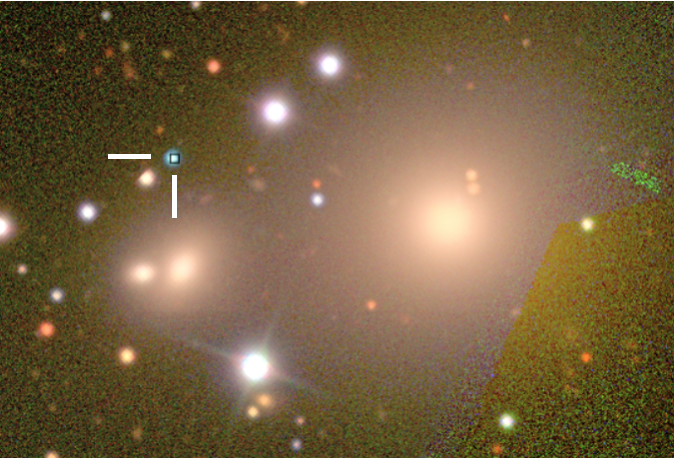

</div>

> **Figure 12:** A larger DP2 color image cutout for the environment of SN 2025imw more clearly shows that extended light from the host galaxy permeates the region, including where SN 2025imw occurred.